In [2]:
import numpy as np
from numpy import cos, sin, exp
import matplotlib.pyplot as plt
import pandas as pd
from dfit import Dfit

### Question 2

In [3]:
df_2 = pd.read_excel('./data2.xlsx')
df_2.columns

Index(['x (cm)', 'y (micro-m)', 'yerr'], dtype='str')

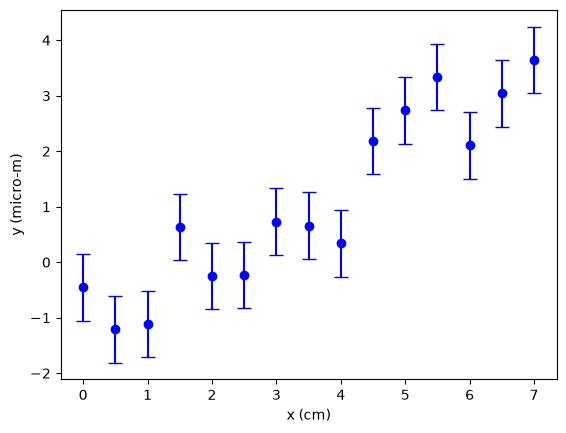

In [4]:
# Convert the dataframe columns to Numpy arrays and make plot.
c0,c1,c2 = list(df_2)    # get the column names
xs_2 = df_2[c0].to_numpy()
ys_2 = df_2[c1].to_numpy()
yerrs_2 = df_2[c2].to_numpy()
plt.errorbar(xs_2,ys_2,yerrs_2,fmt='bo',capsize=5) # plot the data
plt.xlabel(c0)
plt.ylabel(c1)
plt.show()

In [5]:
def linear_fit(x, a, b):
    return a * x + b

def quad_fit(x, a, b, c):
    return a * x**2 + b * x + c

def cub_fit(x, a, b, c, d):
    return a * x**3 + b * x**2 + c * x + d

def quar_fit(x, a, b, c, d, e):
    return a * x**4 + b * x**3 + c * x**2 + d * x + e

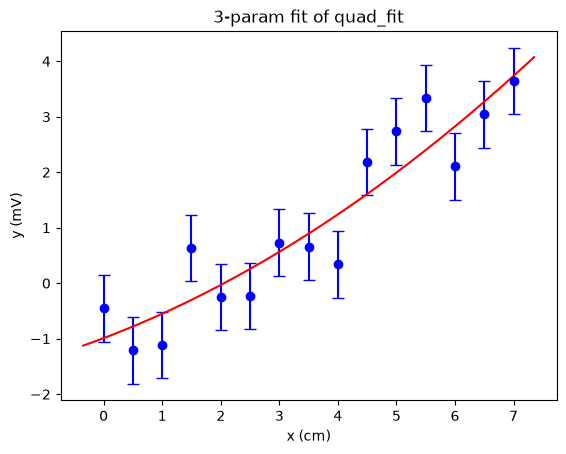

DATA SET: 15 points
FITTING FUNCTION: quad_fit, 3 variable parameters
Chi-squared = 14.38  Reduced chi-squared = 1.198
Parameters and 2-sigma parameter uncertainties:
         a = 0.039218    +/- 0.081813   
         b = 0.40052     +/- 0.59383    
         c = -0.9895     +/- 0.89554    


In [44]:
fit_2 = Dfit(quad_fit,xs_2,ys_2,yerrs_2)
fit_2.plotfit(xlabel=c0,ylabel=c1)
fit_2.printfit()

### Question 3

In [7]:
df_3 = pd.read_excel('./data3.xlsx')
df_3.columns

Index(['x (cm)', 'y (micro-m)'], dtype='str')

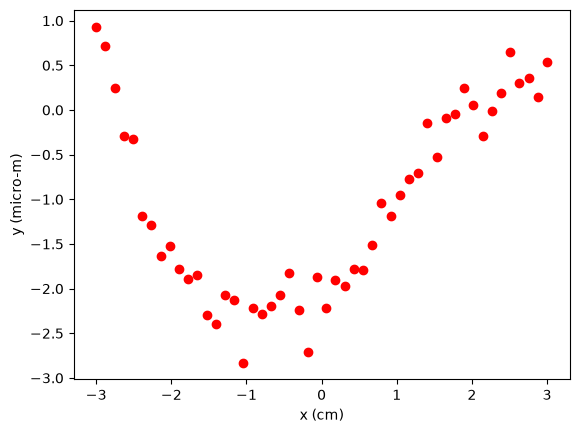

In [8]:
# Convert the dataframe columns to Numpy arrays and make plot.
c0,c1 = list(df_3)    # get the column names
xs_3 = df_3[c0].to_numpy()
ys_3 = df_3[c1].to_numpy()
plt.plot(xs_3, ys_3, 'ro')
plt.xlabel(c0)
plt.ylabel(c1)
plt.show()

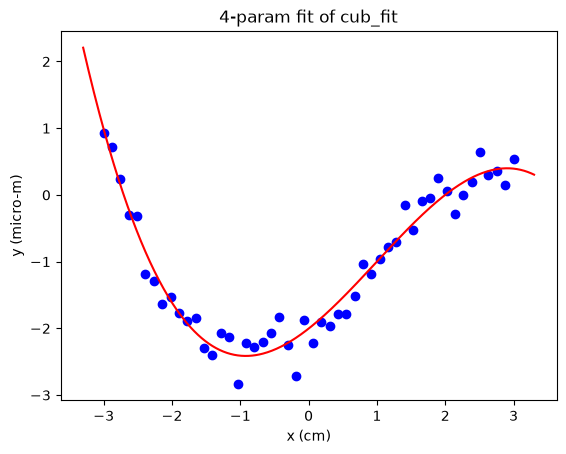

DATA SET: 50 points
FITTING FUNCTION: cub_fit, 4 variable parameters
Chi-squared = 2.512  Reduced chi-squared = 0.0546 (no yerrs supplied)
Parameters and 2-sigma parameter uncertainties:
         a = -0.10046    +/- 0.015282   
         b = 0.29923     +/- 0.023679   
         c = 0.80569     +/- 0.093637   
         d = -2.0035     +/- 0.09917    


In [9]:
fit_3 = Dfit(cub_fit,xs_3,ys_3)
fit_3.plotfit(xlabel=c0,ylabel=c1)
fit_3.printfit()

### Question 4

In [10]:
df_peak = pd.read_excel('./peak4.xlsx')
df_peak.columns

Index(['x (cm)', 'y (mV)'], dtype='str')

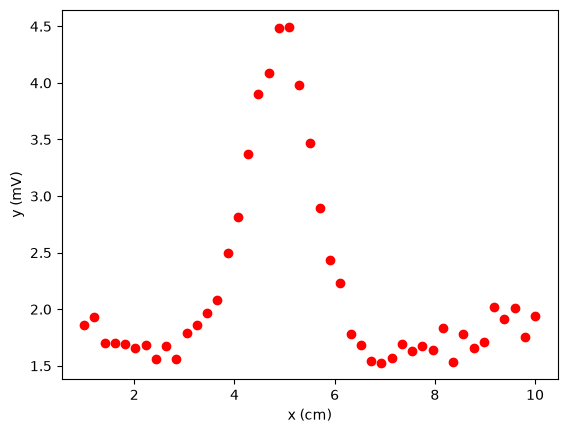

In [11]:
# Convert the dataframe columns to Numpy arrays and make plot.
c0,c1 = list(df_peak)    # get the column names
xs_peak = df_peak[c0].to_numpy()
ys_peak = df_peak[c1].to_numpy()
plt.plot(xs_peak, ys_peak, 'ro')
plt.xlabel(c0)
plt.ylabel(c1)
plt.show()

In [46]:
def gauss_lin(x,aa,x0,w,bb0,bb1):
    """Model function: Gaussian plus linear background"""
    return aa*exp(-(x-x0)**2/(2*w**2)) + bb0 + bb1*x

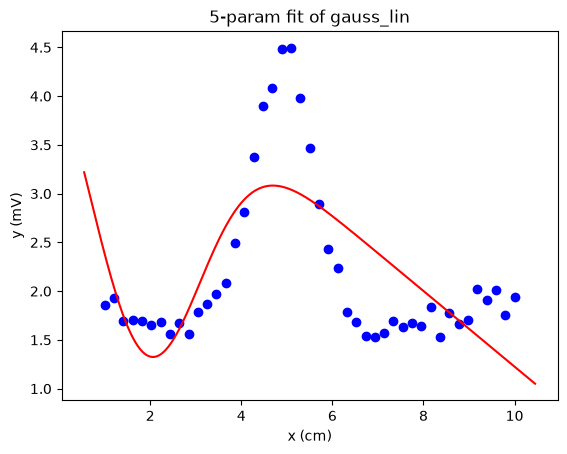

DATA SET: 45 points
FITTING FUNCTION: gauss_lin, 5 variable parameters
Chi-squared = 15.68  Reduced chi-squared = 0.392 (no yerrs supplied)
Parameters and 2-sigma parameter uncertainties:
        aa = -3.0196     +/- 1.0845     
        x0 = 1.8694      +/- 0.41034    
         w = -1.2149     +/- 0.55488    
       bb0 = 5.107       +/- 1.3862     
       bb1 = -0.38815    +/- 0.17882    


In [47]:
guesses = [1, 1, 1, 1, 1]
fit_peak = Dfit(gauss_lin,xs_peak,ys_peak, p0s = guesses)
fit_peak.plotfit(xlabel=c0,ylabel=c1)
fit_peak.printfit()

### Question 5

In [14]:
def gauss_quad(x,aa,x0,w,bb0,bb1,bb2):
    """Model function: Gaussian plus quadratic background"""
    return aa*exp(-(x-x0)**2/(2*w**2)) + bb0 + bb1*x + bb2*x**2

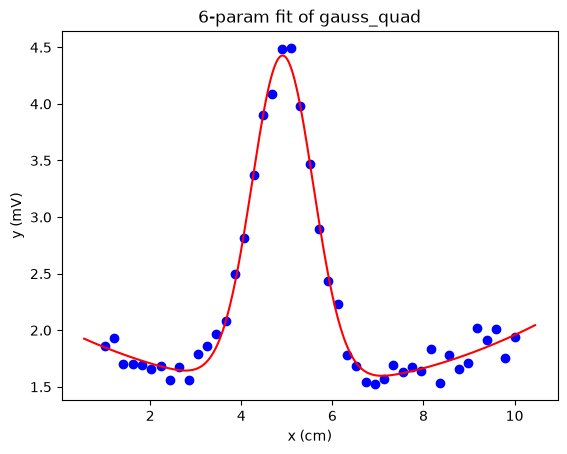

DATA SET: 45 points
FITTING FUNCTION: gauss_quad, 6 variable parameters
Chi-squared = 0.3883  Reduced chi-squared = 0.009957 (no yerrs supplied)
Parameters and 2-sigma parameter uncertainties:
        aa = 2.9134      +/- 0.12026    
        x0 = 4.9076      +/- 0.027628   
         w = 0.67371     +/- 0.035418   
       bb0 = 2.0292      +/- 0.14708    
       bb1 = -0.19922    +/- 0.075386   
       bb2 = 0.019208    +/- 0.0069492  


In [27]:
guesses = [1, 1, 3, 3, 3, -5]
fit_peak = Dfit(gauss_quad,xs_peak,ys_peak, p0s = guesses)
fit_peak.plotfit(xlabel=c0,ylabel=c1)
fit_peak.printfit()

### Question 6

In [31]:
gl1 = pd.read_excel('./gl1.xlsx')

c10,c11 = list(gl1)    # get the column names
xs_gl1 = gl1[c10].to_numpy()
ys_gl1 = gl1[c11].to_numpy()

gl2 = pd.read_excel('./gl2.xlsx')

c20,c21 = list(gl2)    # get the column names
xs_gl2 = gl2[c20].to_numpy()
ys_gl2 = gl2[c21].to_numpy()

In [33]:
def gauss(x,aa,x0,w,bb):
    """Model function: Gaussian plus constant background"""
    return aa*exp(-(x-x0)**2/(2*w**2)) + bb

def lorentz(x, aa, x0, w, bb):
    '''model function: lorentzian plus constant background'''
    return aa / (1 + ((x - x0)/w)**2) + bb

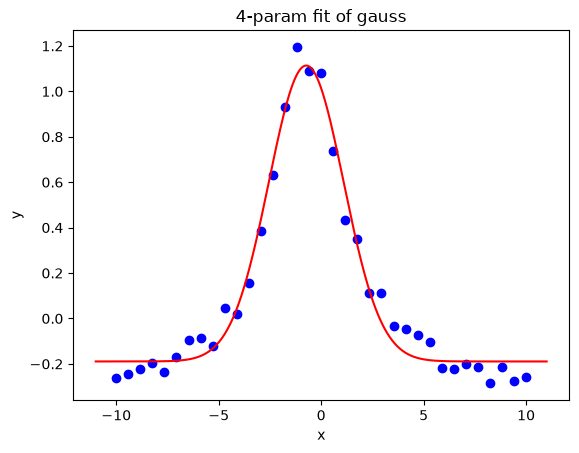

DATA SET: 35 points
FITTING FUNCTION: gauss, 4 variable parameters
Chi-squared = 0.1643  Reduced chi-squared = 0.005302 (no yerrs supplied)
Parameters and 2-sigma parameter uncertainties:
        aa = 1.3028      +/- 0.079755   
        x0 = -0.72948    +/- 0.12298    
         w = 1.8239      +/- 0.14005    
        bb = -0.1892     +/- 0.033845   


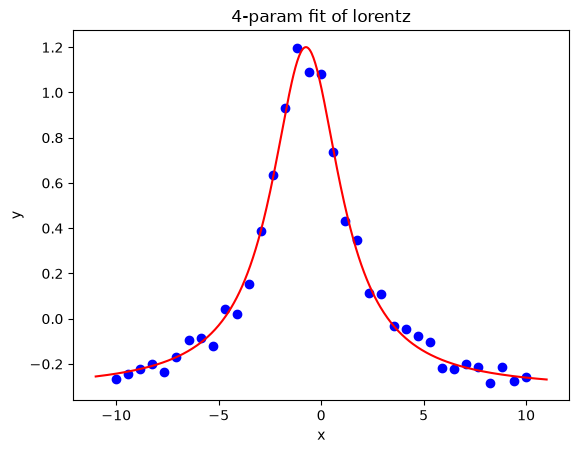

DATA SET: 35 points
FITTING FUNCTION: lorentz, 4 variable parameters
Chi-squared = 0.06324  Reduced chi-squared = 0.00204 (no yerrs supplied)
Parameters and 2-sigma parameter uncertainties:
        aa = 1.5137      +/- 0.056488   
        x0 = -0.74294    +/- 0.073893   
         w = 2.0459      +/- 0.1502     
        bb = -0.31316    +/- 0.029992   


In [38]:
guesses = [1, 1, 1, 1, 1]
fit_gl1 = Dfit(gauss,xs_gl1,ys_gl1, p0s = guesses)
fit_gl1.plotfit(xlabel=c10,ylabel=c11)
fit_gl1.printfit()

guesses = [1, 1, 1, 1, 1]
fit_gl1 = Dfit(lorentz,xs_gl1,ys_gl1, p0s = guesses)
fit_gl1.plotfit(xlabel=c10,ylabel=c11)
fit_gl1.printfit()

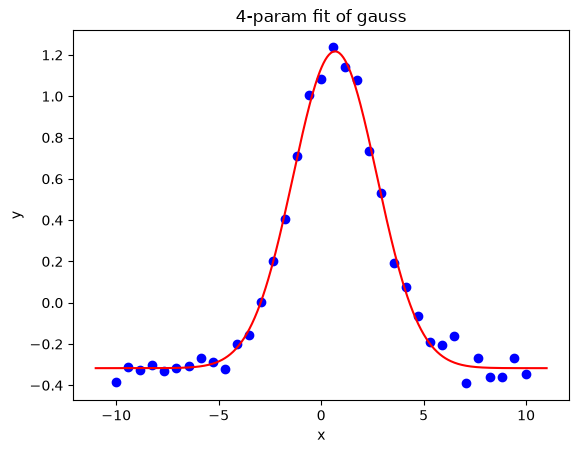

DATA SET: 35 points
FITTING FUNCTION: gauss, 4 variable parameters
Chi-squared = 0.06581  Reduced chi-squared = 0.002123 (no yerrs supplied)
Parameters and 2-sigma parameter uncertainties:
        aa = 1.5342      +/- 0.048212   
        x0 = 0.67728     +/- 0.069976   
         w = 2.0449      +/- 0.081995   
        bb = -0.317      +/- 0.022675   


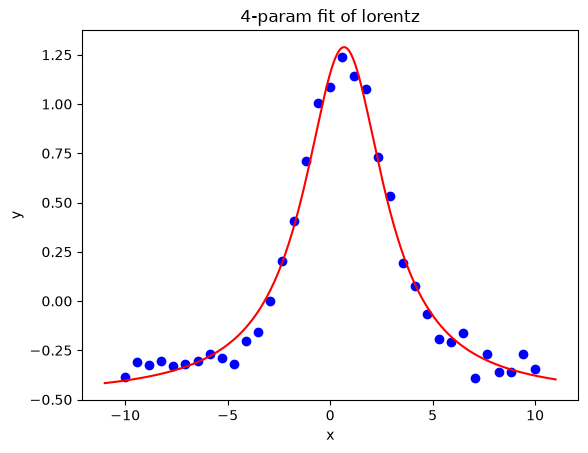

DATA SET: 35 points
FITTING FUNCTION: lorentz, 4 variable parameters
Chi-squared = 0.1428  Reduced chi-squared = 0.004606 (no yerrs supplied)
Parameters and 2-sigma parameter uncertainties:
        aa = 1.7768      +/- 0.080683   
        x0 = 0.67848     +/- 0.10222    
         w = 2.3872      +/- 0.22275    
        bb = -0.48802    +/- 0.050751   


In [39]:
guesses = [1, 1, 1, 1, 1]
fit_gl2 = Dfit(gauss,xs_gl2,ys_gl2, p0s = guesses)
fit_gl2.plotfit(xlabel=c20,ylabel=c21)
fit_gl2.printfit()

guesses = [1, 1, 1, 1, 1]
fit_gl2 = Dfit(lorentz,xs_gl2,ys_gl2, p0s = guesses)
fit_gl2.plotfit(xlabel=c20,ylabel=c21)
fit_gl2.printfit()

### Question 9

In [9]:
df_ligo = pd.read_csv('./H1-STRAIN-1126259462-0.csv')

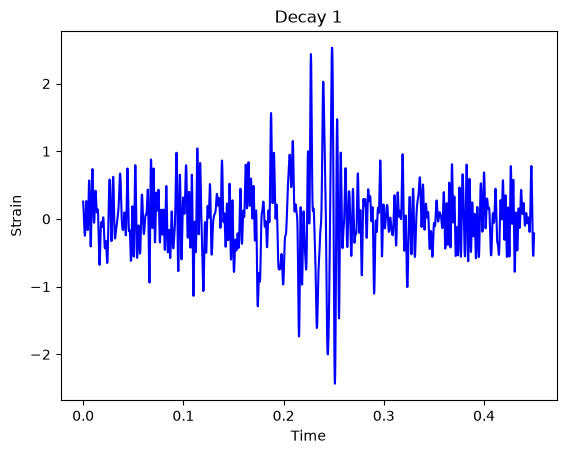

In [16]:
c0,c1 = list(df_ligo)
xs = df_ligo[c0].to_numpy()
ys = df_ligo[c1].to_numpy()
ts = xs - xs[0]
plt.plot(ts,ys,c='b')
plt.xlabel(c0)
plt.ylabel(c1)
plt.title('Decay 1')
plt.show()

In [ ]:
def chirp_model(t, )